# 02 · Event impact across games: the analysis step by step

Three games in the sample went through a big change at a known date:

| Game | Cutoff | Event |
|---|---|---|
| Counter-Strike | 2023-09-29 | CS2 replaces CS:GO |
| PUBG: BATTLEGROUNDS | 2022-03-23 | becomes free to play |
| The Sims 4 | 2022-10-18 | base game becomes free to play |

Notebook 01 produced a full report with one call. Here we use the **building blocks**
behind `run_analysis` instead, so the three games can be put side by side and the
analysis extended with our own questions:

- `analysis.text`: game-aware preprocessing (`PreprocessingConfig`) and word frequencies
- `analysis.sentiment`: VADER scores and categories
- `analysis.dataset`: before/after splits, periods and years
- `analysis.statistics`: yearly means, correlations, engagement split
- `analysis.plotting`: matplotlib figures that accept an `ax`, so they compose into grids

## Setup

In [1]:
import logging
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

import steam_review_analysis as sra
from steam_review_analysis.analysis.dataset import add_period, add_year, load_reviews, split_by_cutoff
from steam_review_analysis.analysis.nltk_resources import ensure_nltk_resources
from steam_review_analysis.analysis.plotting import plot_sentiment_distribution, plot_word_frequencies
from steam_review_analysis.analysis.presets import load_presets
from steam_review_analysis.analysis.sentiment import add_sentiment, sentiment_summary
from steam_review_analysis.analysis.statistics import engagement_split, pearson_correlations, yearly_mean
from steam_review_analysis.analysis.text import (
    PreprocessingConfig,
    prepare_documents,
    preprocess_text,
    word_frequencies,
)

logging.basicConfig(level=logging.WARNING)
pd.set_option("display.precision", 3)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"

ensure_nltk_resources(download=True)
presets = load_presets(PROJECT_ROOT / "configs" / "presets.toml")
EVENTS = {
    "Counter_Strike": "CS2 replaces CS:GO",
    "PUBG": "PUBG goes free to play",
    "SIMS": "The Sims 4 goes free to play",
}

The processed dataset is created in notebook 01. If it is missing, rebuild it from the
bundled sample so this notebook also runs on its own.

In [2]:
if not (PROCESSED_DIR / "reviews.csv").exists():
    games = sra.load_games(PROJECT_ROOT / "configs" / "games.toml")
    games[730] = sra.Game(730, "Counter-Strike 2")
    sra.write_processed(sra.clean_reviews(sra.read_raw_reviews(DATA_DIR / "cleaned"), games), PROCESSED_DIR)

sra.read_processed(PROCESSED_DIR).groupby(["app_id", "game"]).size().rename("reviews")

app_id   game               
730      Counter-Strike 2       757
578080   PUBG: BATTLEGROUNDS    757
1222670  The Sims 4             606
Name: reviews, dtype: int64

## 1. Game-aware preprocessing

`preprocess_text` lowercases, removes stopwords and lemmatizes. A `PreprocessingConfig`
adds domain knowledge: keywords that must survive (`fpp`, `dlc`, ...) and replacements
that merge synonyms. Compare the default with the PUBG preset on one sentence:

In [3]:
sentence = "Hackers and cheaters with an aimbot in every match, FPP squads are unplayable. Not fun!"

with pd.option_context("display.max_colwidth", 120):
    display(pd.Series({
        "original": sentence,
        "default config": preprocess_text(sentence),
        "PUBG preset": preprocess_text(sentence, presets["PUBG"].preprocessing),
    }).to_frame("text"))

,text
original,"Hackers and cheaters with an aimbot in every match, FPP squads are unplayable. Not fun!"
default config,hacker cheater aimbot every match fpp squad unplayable fun
PUBG preset,cheat cheat cheat every match fpp squad unplayable fun


Without the preset, *hacker*, *cheater* and *aimbot* are counted as three different words.
With it they all become `cheat`, which is what we want to count when the question is
"did complaints about cheating change?". Replacements apply to the **lemmatized** word, so
a rule must use the singular form (`aimbot`, not `aimbots`). Also note that *not* is gone:
good for word counts, but it matters for sentiment (see notebook 03).

Now prepare and score all three games with their own preset. `prepare_documents` adds a
`processed_review` (for sentiment) and a vocabulary-filtered `document` (for word counts);
`add_sentiment`, `add_year` and `add_period` each return a new frame with extra columns.

In [4]:
scored = {}
for name, preset in presets.items():
    reviews = load_reviews(preset.app_id, PROCESSED_DIR)
    prepared = prepare_documents(reviews, preset.preprocessing)
    frame = add_period(add_year(add_sentiment(prepared.reviews)), preset.cutoff)
    frame["game"] = name
    scored[name] = frame

all_reviews = pd.concat(scored.values(), ignore_index=True)
all_reviews[["game", "date", "period", "recommendation", "sentiment_score", "sentiment_category", "document"]].sample(5, random_state=1)

,game,date,period,recommendation,sentiment_score,sentiment_category,document
623,Counter_Strike,2023-10-07,After,Recommended,0.000,Neutral,bring back cs
1225,PUBG,2021-10-18,Before,Recommended,0.974,Positive,product receive free give game free christmas ...
396,Counter_Strike,2020-11-25,Before,Recommended,0.710,Positive,create review steam award
680,Counter_Strike,2024-03-24,After,Not Recommended,-0.992,Negative,long time player far say valve drop ball large...
950,PUBG,2018-06-20,Before,Not Recommended,0.293,Positive,money make machine skin lootboxes less optimiz...


## 2. Before vs after, side by side

Two views of "how players feel": the reviewer's own **recommendation** and the
**VADER** score of the text. `sentiment_summary` gives the score and category shares for
any slice of reviews.

In [5]:
rows = []
for (name, period), group in all_reviews.groupby(["game", "period"]):
    rows.append({
        "game": name,
        "period": period,
        "reviews": len(group),
        "recommended": group["is_recommended"].mean(),
        **{k: v for k, v in sentiment_summary(group).items() if k != "count"},
    })
overview = pd.DataFrame(rows).set_index(["game", "period"]).reindex(["Before", "After"], level=1)
overview

reviews  recommended  mean_score  positive_share  \
game           period                                                     
Counter_Strike Before      616        0.877       0.135           0.524   
               After       124        0.589      -0.037           0.435   
PUBG           Before      538        0.355       0.036           0.467   
               After       206        0.422       0.043           0.519   
SIMS           Before      329        0.650       0.331           0.653   
               After       275        0.684       0.327           0.633   

                       neutral_share  negative_share  
game           period                                 
Counter_Strike Before          0.154           0.321  
               After           0.137           0.427  
PUBG           Before          0.102           0.431  
               After           0.049           0.432  
SIMS           Before          0.128           0.219  
               After           0.153           0.215

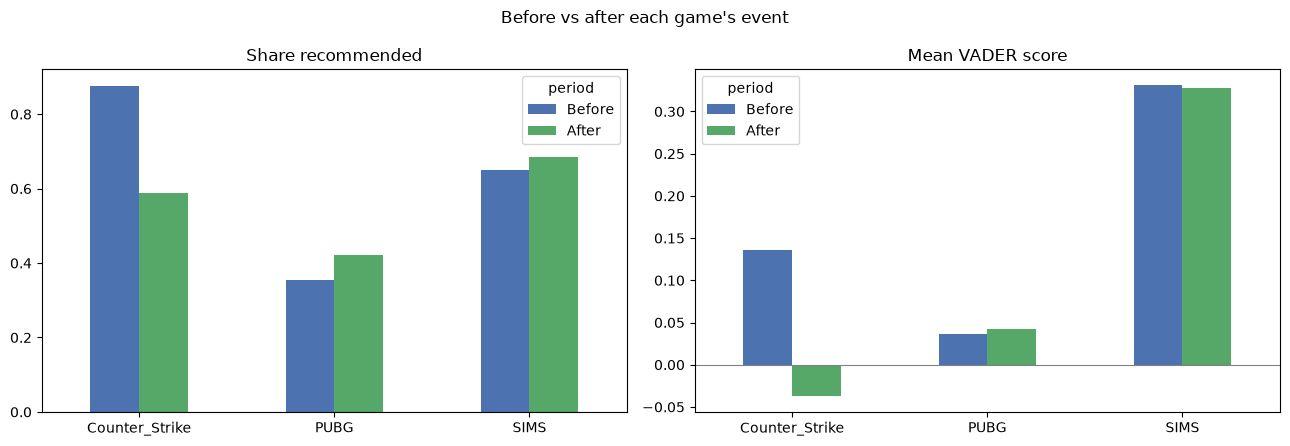

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, column, label in zip(axes, ["recommended", "mean_score"], ["Share recommended", "Mean VADER score"]):
    overview[column].unstack("period")[["Before", "After"]].plot.bar(ax=ax, rot=0, color=["#4C72B0", "#55A868"])
    ax.set_title(label)
    ax.set_xlabel("")
    ax.axhline(0, color="grey", linewidth=0.8)
fig.suptitle("Before vs after each game's event")
fig.tight_layout()

The package's own plots work per game and accept an `ax`, so they combine into one figure:

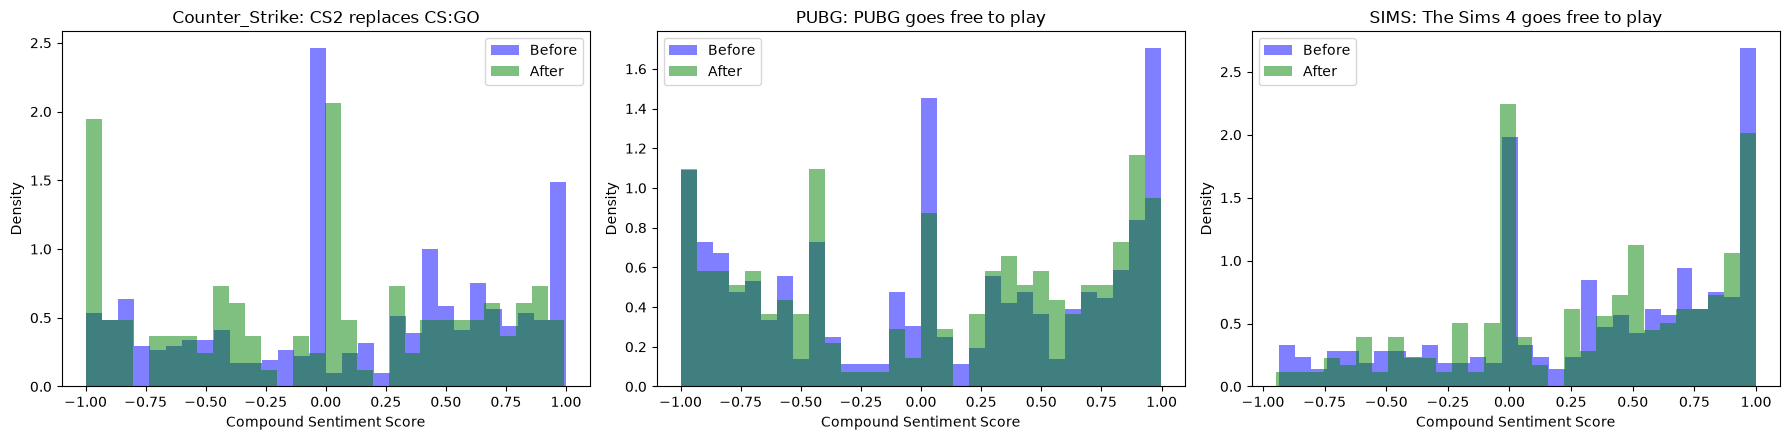

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (name, frame) in zip(axes, scored.items()):
    before, after = split_by_cutoff(frame, presets[name].cutoff)
    plot_sentiment_distribution(before["sentiment_score"], after["sentiment_score"], cutoff=presets[name].cutoff, ax=ax)
    ax.set_title(f"{name}: {EVENTS[name]}")
fig.tight_layout()

## 3. What did people talk about?

Raw top-word lists are dominated by words like `game` and `play` in both periods. A more
useful question is **which words gained or lost ground** after the event.

Counting every occurrence lets a single long or copy-pasted review dominate, so we count
each word **once per review** (by passing de-duplicated documents to `word_frequencies`)
and compare the share of reviews that mention it.

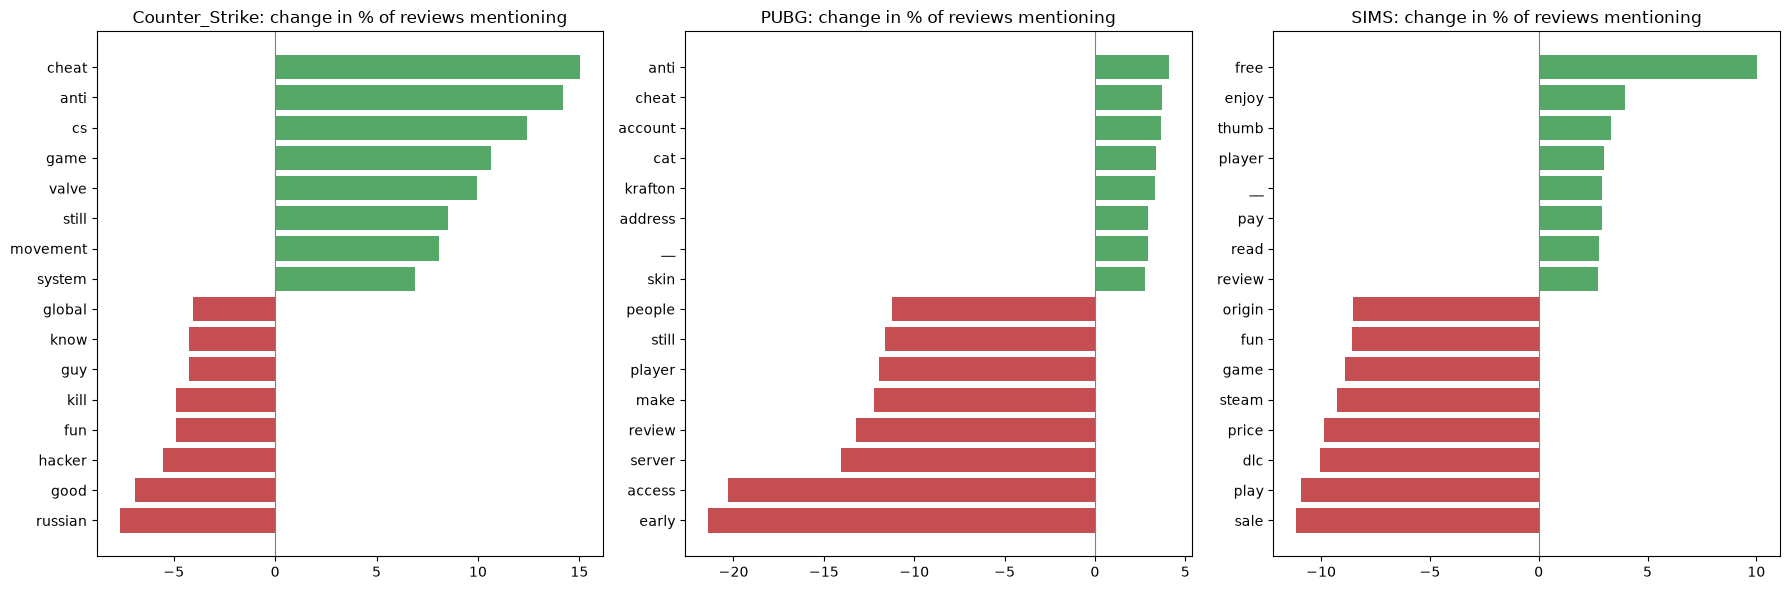

In [8]:
def word_shift(frame: pd.DataFrame, cutoff: str, top: int = 8) -> pd.DataFrame:
    """Words whose share of mentioning reviews rose or fell most after the cutoff."""
    before, after = split_by_cutoff(frame, cutoff)
    shares = {}
    for period, part in (("before", before), ("after", after)):
        unique_words = part["document"].map(lambda doc: " ".join(set(doc.split())))
        counts = word_frequencies(unique_words).set_index("word")["frequency"]
        shares[period] = counts / len(part) * 100
    table = pd.DataFrame(shares).fillna(0)
    table = table[table.index.str.isascii()]  # skip CJK words the default font cannot draw
    table["change"] = table["after"] - table["before"]
    return pd.concat([table.nlargest(top, "change"), table.nsmallest(top, "change")])


shifts = {name: word_shift(frame, presets[name].cutoff) for name, frame in scored.items()}
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (name, table) in zip(axes, shifts.items()):
    ordered = table.sort_values("change")
    ax.barh(ordered.index, ordered["change"], color=["#C44E52" if v < 0 else "#55A868" for v in ordered["change"]])
    ax.set_title(f"{name}: change in % of reviews mentioning")
    ax.axvline(0, color="grey", linewidth=0.8)
fig.tight_layout()

For a closer look at one game, the standard frequency chart from the package, before and
after the cutoff:

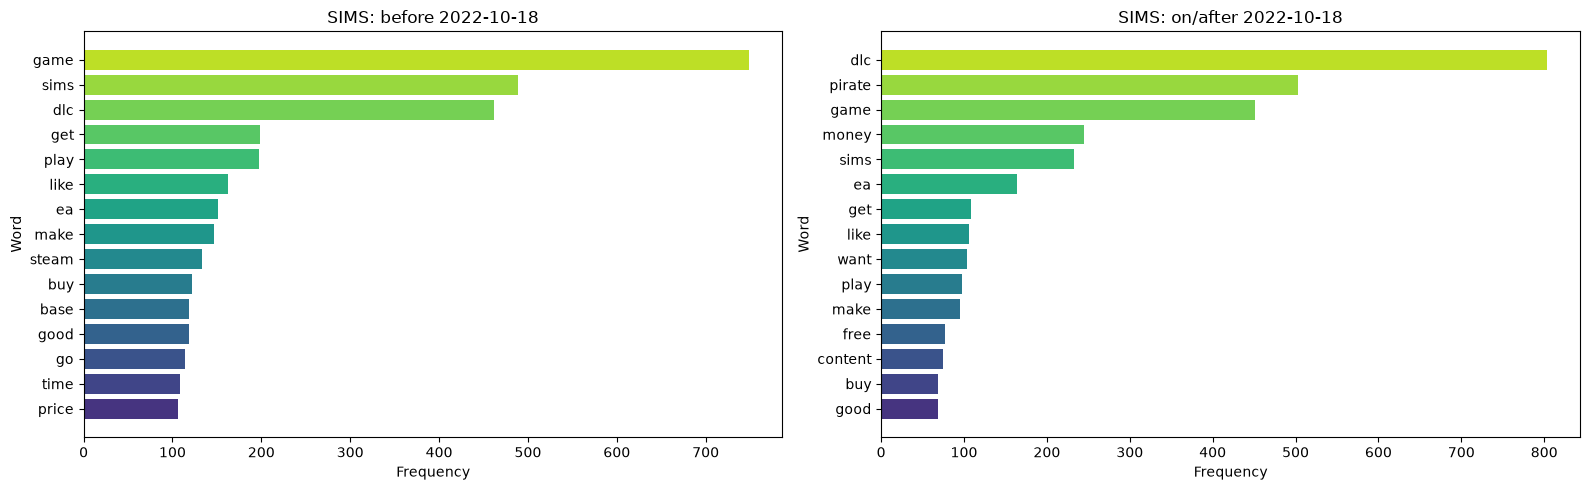

In [9]:
name = "SIMS"
before, after = split_by_cutoff(scored[name], presets[name].cutoff)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
plot_word_frequencies(word_frequencies(before["document"], top_n=15), title=f"{name}: before {presets[name].cutoff}", ax=axes[0])
plot_word_frequencies(word_frequencies(after["document"], top_n=15), title=f"{name}: on/after {presets[name].cutoff}", ax=axes[1])
fig.tight_layout()

## 4. Trends over time

`yearly_mean` averages any numeric column per year. The cutoff is a single date, but the
yearly view shows whether a change was a step at the event or a longer trend.

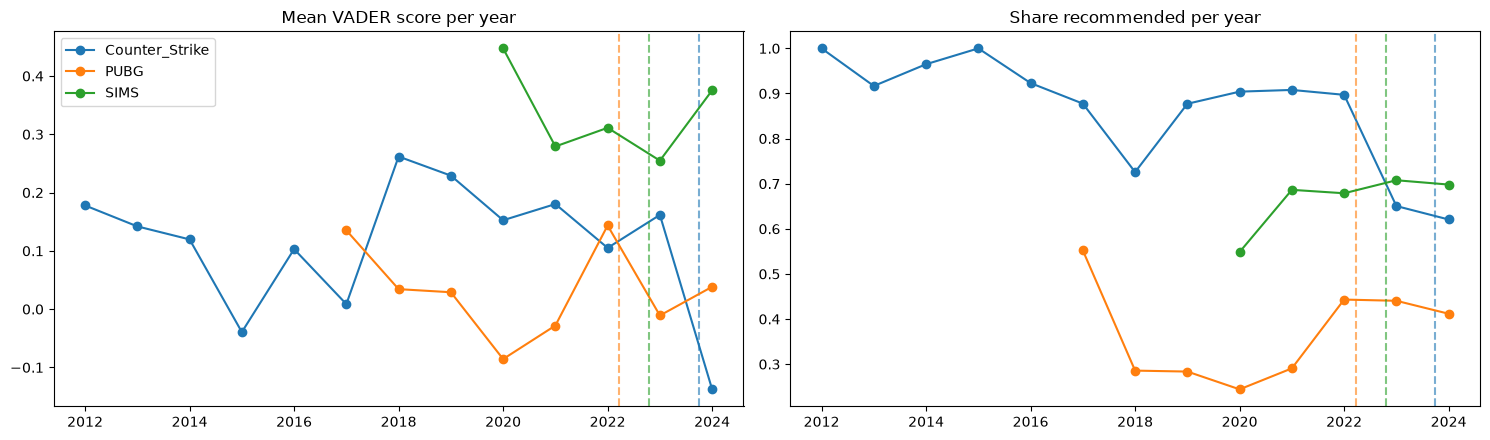

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharex=True)
for name, frame in scored.items():
    cutoff_year = pd.Timestamp(presets[name].cutoff).year + pd.Timestamp(presets[name].cutoff).dayofyear / 365
    for ax, column in zip(axes, ["sentiment_score", "is_recommended"]):
        yearly = yearly_mean(frame.astype({"is_recommended": float}), value_column=column)
        line, = ax.plot(yearly["year"], yearly[column], marker="o", label=name)
        ax.axvline(cutoff_year, color=line.get_color(), linestyle="--", alpha=0.6)
axes[0].set_title("Mean VADER score per year")
axes[1].set_title("Share recommended per year")
axes[0].legend()
fig.tight_layout()

Dashed lines mark each game's event. Reviews per year, to judge how much each point can be trusted:

In [11]:
all_reviews.pivot_table(index='game', columns='year', values='text', aggfunc='size', fill_value=0)

year,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
game,,,,,,,,,,,,,
Counter_Strike,1,12,57,43,52,49,62,57,73,76,68,103,87
PUBG,0,0,0,0,0,125,140,67,86,86,88,84,68
SIMS,0,0,0,0,0,0,0,0,113,118,137,130,106


## 5. Who is writing: playtime and helpful votes

`pearson_correlations` measures how sentiment relates to playtime and helpful votes in each
period. `engagement_split` labels reviewers above the game's median playtime as *engaged*.

In [12]:
pd.concat(
    {name: pearson_correlations(frame, presets[name].cutoff).set_index("comparison") for name, frame in scored.items()}
)

before  after
               comparison                                     
Counter_Strike sentiment_score vs hours_played    0.038 -0.134
               sentiment_score vs helpful_votes  -0.107 -0.054
PUBG           sentiment_score vs hours_played   -0.067 -0.096
               sentiment_score vs helpful_votes  -0.111  0.079
SIMS           sentiment_score vs hours_played    0.050 -0.003
               sentiment_score vs helpful_votes  -0.075 -0.038

In [13]:
engaged = pd.concat(engagement_split(frame) for frame in scored.values())
engaged.pivot_table(
    index="game",
    columns=["period", "engaged"],
    values="is_recommended",
    aggfunc="mean",
).reindex(columns=["Before", "After"], level=0).rename(columns={False: "casual", True: "engaged"})

period         Before          After        
engaged        casual engaged casual engaged
game                                        
Counter_Strike  0.885   0.869  0.720   0.388
PUBG            0.391   0.321  0.450   0.389
SIMS            0.552   0.750  0.672   0.696

## Takeaways and caveats

- The package functions return plain DataFrames and figures, so cross-game comparisons
  and custom metrics (like the word shift above) take only a few lines.
- Presets matter: merging synonyms changes which words make the top lists.
- The sample is small (600–760 reviews per game) and Steam lists reviews by helpfulness,
  not at random, so these numbers describe this sample, not every player. Some years have
  few reviews, as the count table shows.
- VADER reads processed, lemmatized text with stopwords removed, which drops negations such
  as *not*. Notebook **03** measures how much that costs and compares VADER with the
  transformer models.